# Getting Audio Data

In [202]:
import librosa
from IPython.display import Audio

audio, sr = librosa.load("sample_Data/Czesc3.wav", sr=16000, mono=True, duration=17)

# Play the audio file used in the recognition
Audio(audio, rate=sr)

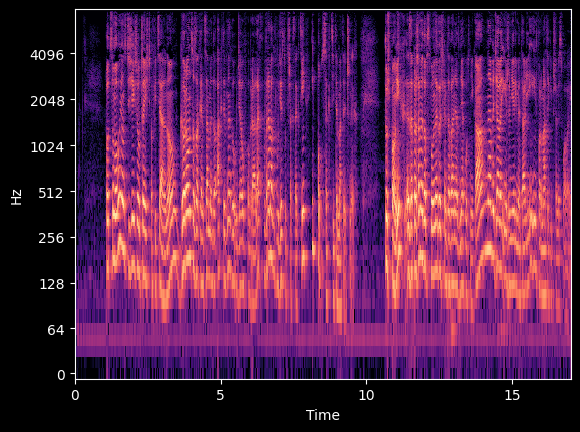

In [203]:
import numpy as np
import matplotlib.pyplot as plt

S = np.abs(librosa.stft(audio, n_fft=1024, hop_length=256))
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max), sr=sr, hop_length=256, x_axis='time', y_axis='log')
plt.show()

# Nemo Model

In [204]:
import torch

device = "mps" if torch.backends.mps.is_available() else "cpu"

asr_model.to(device)

EncDecHybridRNNTCTCBPEModel(
  (preprocessor): AudioToMelSpectrogramPreprocessor(
    (featurizer): FilterbankFeatures()
  )
  (encoder): ConformerEncoder(
    (pre_encode): ConvSubsampling(
      (out): Linear(in_features=2560, out_features=512, bias=True)
      (conv): Sequential(
        (0): Conv2d(1, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=256)
        (3): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
        (4): ReLU(inplace=True)
        (5): Conv2d(256, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=256)
        (6): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
        (7): ReLU(inplace=True)
      )
    )
    (pos_enc): RelPositionalEncoding(
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (layers): ModuleList(
      (0-16): 17 x ConformerLayer(
        (norm_feed_forward1): LayerNorm((512,), eps=1e-05, 

In [205]:
import nemo.collections.asr as nemo_asr
import warnings

warnings.filterwarnings("ignore")

# Load the Polish-specific model
asr_model = nemo_asr.models.EncDecHybridRNNTCTCBPEModel.from_pretrained(
    model_name="nvidia/stt_pl_fastconformer_hybrid_large_pc"
)

[NeMo I 2026-05-16 16:58:39 nemo_logging:381] Tokenizer SentencePieceTokenizer initialized with 1024 tokens


[NeMo W 2026-05-16 16:58:40 nemo_logging:393] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath:
    - /datasets/pl_asr_dataset/mcv-train.json
    - /datasets/pl_asr_dataset/mls-train.json
    - /datasets/pl_asr_dataset/voxpopuli-train.json
    sample_rate: 16000
    batch_size: 64
    shuffle: true
    num_workers: 8
    pin_memory: true
    use_start_end_token: false
    trim_silence: false
    max_duration: 20
    min_duration: 0.1
    is_tarred: false
    tarred_audio_filepaths: null
    shuffle_n: 2048
    bucketing_strategy: synced_randomized
    bucketing_batch_size: null
    
[NeMo W 2026-05-16 16:58:40 nemo_logging:393] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the validation data loa

[NeMo I 2026-05-16 16:58:40 nemo_logging:381] PADDING: 0
[NeMo I 2026-05-16 16:58:40 nemo_logging:381] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}
[NeMo I 2026-05-16 16:58:40 nemo_logging:381] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}


[NeMo W 2026-05-16 16:58:40 nemo_logging:393] No conditional node support for Cuda.
    Cuda graphs with while loops are disabled, decoding speed will be slower
    Reason: CUDA is not available


[NeMo I 2026-05-16 16:58:40 nemo_logging:381] Using RNNT Loss : warprnnt_numba
    Loss warprnnt_numba_kwargs: {'fastemit_lambda': 0.0, 'clamp': -1.0}


[NeMo W 2026-05-16 16:58:40 nemo_logging:393] No conditional node support for Cuda.
    Cuda graphs with while loops are disabled, decoding speed will be slower
    Reason: CUDA is not available


[NeMo I 2026-05-16 16:58:40 nemo_logging:381] Model EncDecHybridRNNTCTCBPEModel was successfully restored from /Users/dominikmika/.cache/huggingface/hub/models--nvidia--stt_pl_fastconformer_hybrid_large_pc/snapshots/90fc78a3d35d7140255f95d4c71cc5593f2d0c4e/stt_pl_fastconformer_hybrid_large_pc.nemo.


In [206]:
from omegaconf import OmegaConf, DictConfig

OmegaConf.set_struct(asr_model.cfg.aux_ctc.decoding, False)
asr_model.cfg.aux_ctc.decoding.preserve_alignments = True
asr_model.cfg.aux_ctc.decoding.compute_timestamps = True
asr_model.cfg.aux_ctc.decoding.confidence_cfg = DictConfig({
    "preserve_frame_confidence": True,
    "preserve_token_confidence": True,
    "preserve_word_confidence": True,
    "exclude_blank": True,
    "aggregation": "mean",
    "method_cfg": {
        "name": "entropy",
        "entropy_type": "tsallis",
        "alpha": 0.33,
        "entropy_norm": "exp",
    }
})
OmegaConf.set_struct(asr_model.cfg.aux_ctc.decoding, True)

asr_model.change_decoding_strategy(asr_model.cfg.aux_ctc.decoding, decoder_type="ctc")

hyp = asr_model.transcribe([audio], return_hypotheses=True)[0][0]

[NeMo I 2026-05-16 16:58:40 nemo_logging:381] Changed decoding strategy of the CTC decoder to 
    strategy: greedy
    preserve_alignments: true
    compute_timestamps: true
    word_seperator: ' '
    ctc_timestamp_type: all
    batch_dim_index: 0
    greedy:
      preserve_alignments: false
      compute_timestamps: false
      preserve_frame_confidence: false
      confidence_method_cfg:
        name: entropy
        entropy_type: tsallis
        alpha: 0.33
        entropy_norm: exp
        temperature: DEPRECATED
    beam:
      beam_size: 4
      search_type: default
      preserve_alignments: false
      compute_timestamps: false
      return_best_hypothesis: true
      beam_alpha: 1.0
      beam_beta: 0.0
      kenlm_path: null
      flashlight_cfg:
        lexicon_path: null
        boost_path: null
        beam_size_token: 16
        beam_threshold: 20.0
        unk_weight: -.inf
        sil_weight: 0.0
      pyctcdecode_cfg:
        beam_prune_logp: -10.0
        token_min_

Transcribing: 100%|██████████| 1/1 [00:00<00:00,  4.58it/s]


In [207]:
with open("sample_Data/Czesc3_17s.txt", 'r', encoding='utf-8') as file:
    reference = file.read()

print(f"Reference: {reference}\n")
print(f"Transcription: {hyp.text}")

Reference: Podsumowując dzisiejszą część oficjalną, gorąco zachęcamy do aktywnego udziału w obradach w ramach dwudziestu trzech sekcji i podsekcji tematycznych. Tuż po nich zapraszamy do wspólnego świętowania dnia hutnika na wydziale inżynierii metali i informatyki przemysłowej.

Transcription: Podsumowując dzisiejszą część oficjalną , gorąco zachęcamy do aktywnego udziału w obradach w ramach dwudziestu trzechsekcji i posekcji tematycznych . Tuż po nich zapraszamy do wspólnego świętowania dnia hutnika na wydziale inżynieriietali i informatyki przemysłowej .


In [208]:
# Confidence metric: overall certainty about speech transcript, low confidence indicates potential babbling.

conf = 1-np.exp(hyp.score)
conf

tensor(0.9997)

In [211]:
# Word confidence metric: per-word certainty from the ASR model, pinpoints the exact words where articulation broke down.

frame_duration = 0.01

for entry, word_conf in zip(hyp.timestep['word'], hyp.word_confidence):
    word = entry['word']
    start_s = entry['start_offset'] * frame_duration
    end_s = entry['end_offset'] * frame_duration
    print(f"{word:25s} {start_s:.2f}s – {end_s:.2f}s  conf={word_conf:.3f}")

Podsumowując              0.00s – 0.20s  conf=0.727
dzisiejszą                0.20s – 0.27s  conf=0.809
część                     0.27s – 0.31s  conf=0.677
oficjalną                 0.31s – 0.40s  conf=0.721
,                         0.40s – 0.44s  conf=0.320
gorąco                    0.44s – 0.49s  conf=0.682
zachęcamy                 0.49s – 0.58s  conf=0.631
do                        0.58s – 0.59s  conf=0.771
aktywnego                 0.59s – 0.67s  conf=0.765
udziału                   0.67s – 0.72s  conf=0.688
w                         0.72s – 0.73s  conf=0.794
obradach                  0.73s – 0.79s  conf=0.664
w                         0.79s – 0.80s  conf=0.749
ramach                    0.80s – 0.85s  conf=0.656
dwudziestu                0.85s – 0.91s  conf=0.624
trzechsekcji              0.91s – 0.99s  conf=0.249
i                         0.99s – 1.01s  conf=0.368
posekcji                  1.01s – 1.10s  conf=0.327
tematycznych              1.10s – 1.19s  conf=0.117
.           

In [210]:
# Character Error Rate (CER): measures what fraction of letters were misrecognized, where a single letter swap signals poor articulation. Particularly important for Polish as it quantifies ą/a, ę/e, ź/ż/z differences.

from jiwer import cer

cer_score = cer(reference, hyp.text)
cer_score

0.026119402985074626